In [1]:


import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings("ignore")

# Output folder
OUT = "malaria_outputs"
os.makedirs(OUT, exist_ok=True)

# Dataset
PATH = r"C:\Users\HP\Downloads\New folder (7)\Malaria_Asia data.xlsx"

# Training and testing
TRAIN_END = 2016
FORECAST_YEARS = list(range(2023, 2029))

# Settings
CI_LEVEL = 0.95
SELECT_BY = "MAE"
VIF_MAX = 10
CLUSTER_SE = True

# Random seed
RNG = np.random.default_rng(42)

# Plot settings
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True

In [2]:
raw = pd.read_excel(PATH, sheet_name="Asia")

YCOLS = [f"y{i}" for i in range(1, 23)]

df = raw[["Country", "Year", "Malaria cases"] + YCOLS]
df = df.rename(columns={"Malaria cases": "cases"})

df = df.sort_values(["Country", "Year"])
df["cases"] = df["cases"].astype(int)

COUNTRIES = sorted(df["Country"].unique())

var = pd.read_excel(PATH, sheet_name="variable", header=None)

LABEL = dict(zip(var[2], var[1]))

print(df.shape)
print("Countries:", len(COUNTRIES))
print("Years:", df.Year.min(), "-", df.Year.max())

df.head()

(667, 25)
Countries: 29
Years: 2000 - 2022


,Country,Year,cases,y1,y2,y3,y4,y5,y6,y7,...,y13,y14,y15,y16,y17,y18,y19,y20,y21,y22
0,Afghanistan,2000,1312939,0.00,0.30,2.084,0.000,6.88,4.4,20130327,...,57.945817,27,20.97,36.633333,54.98949,131.6,64.767280,26.0,28.7,18.2
1,Afghanistan,2001,1312939,2.02,0.39,2.084,2.084,6.88,9.3,20284307,...,57.945817,27,20.98,36.733333,46.57054,0.0,64.597573,26.0,28.7,18.2
2,Afghanistan,2002,1382972,0.00,0.39,5.303,5.303,1.21,14.1,21378117,...,57.945817,30,22.54,36.900000,46.57054,0.0,64.416888,26.0,28.7,18.2
3,Afghanistan,2003,1242906,0.00,0.39,5.575,5.575,5.46,19.0,22733049,...,57.945817,32,24.10,37.033333,46.57054,0.0,64.176231,26.0,28.7,18.2
4,Afghanistan,2004,716954,0.00,0.39,27.647,27.647,3.60,23.8,23560654,...,57.945817,34,25.67,37.233333,46.57054,0.0,63.826609,26.0,28.7,18.2


In [3]:
df.describe()

,Year,cases,y1,y2,y3,y4,y5,y6,y7,y8,...,y13,y14,y15,y16,y17,y18,y19,y20,y21,y22
count,667.000000,6.670000e+02,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,6.670000e+02,667.000000,...,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000,667.000000
mean,2011.000000,6.221875e+05,11.358276,2.220975,18.706745,18.703621,7.061334,71.003898,1.198223e+08,5.606506,...,39.571741,82.598201,73.870135,36.774513,55.264247,11.599700,29.491522,8.795202,9.070315,8.022789
std,6.638228,2.868244e+06,12.897377,1.882091,14.128127,14.132038,3.567235,38.303948,3.268990e+08,5.484734,...,21.786258,19.820376,23.478778,6.661077,9.398347,18.851258,19.480292,19.487601,19.801422,19.055516
min,2000.000000,0.000000e+00,0.000000,0.000000,0.281000,0.000000,1.210000,0.000000,0.000000e+00,0.000000,...,3.789984,0.000000,0.000000,23.033333,46.570540,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2005.000000,0.000000e+00,0.000000,0.720000,5.672000,5.672000,4.510000,45.600000,2.487298e+06,2.029013,...,22.888366,80.000000,56.350000,30.733333,46.570540,0.000000,18.358480,0.000000,0.000000,0.000000
50%,2011.000000,1.825000e+03,6.610000,1.840000,18.011000,18.011000,6.630000,93.800000,1.922467e+07,5.357403,...,34.684867,89.000000,82.410000,37.566667,51.493350,0.000000,27.372916,0.000000,0.000000,0.000000
75%,2017.000000,6.803150e+04,20.025000,3.475000,28.227500,28.227500,8.810000,99.800000,4.013302e+07,7.481175,...,57.945817,95.500000,93.695000,42.566667,60.682520,21.000000,42.525349,3.000000,4.000000,1.000000
max,2022.000000,2.425497e+07,75.100000,7.820000,75.553000,75.553000,26.110000,100.000000,1.425423e+09,58.078096,...,84.563658,100.000000,99.820000,48.166667,77.698800,131.600000,79.037396,83.000000,90.300000,82.800000


In [4]:
case_mean = df["cases"].mean()
case_var = df["cases"].var()

print("Mean:", case_mean)
print("Variance:", case_var)


Mean: 622187.4902548726
Variance: 8226824972163.039


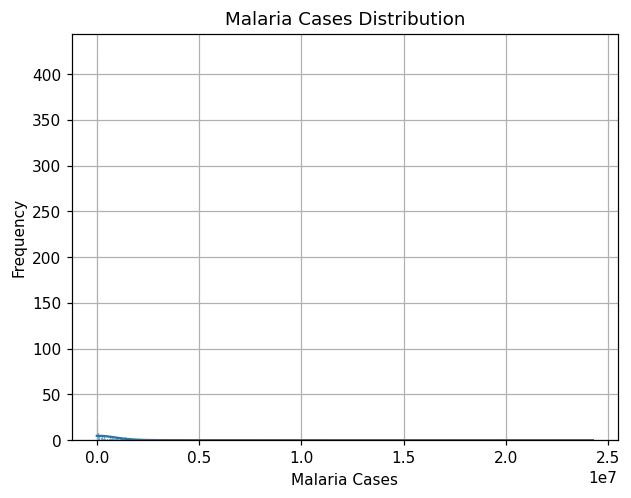

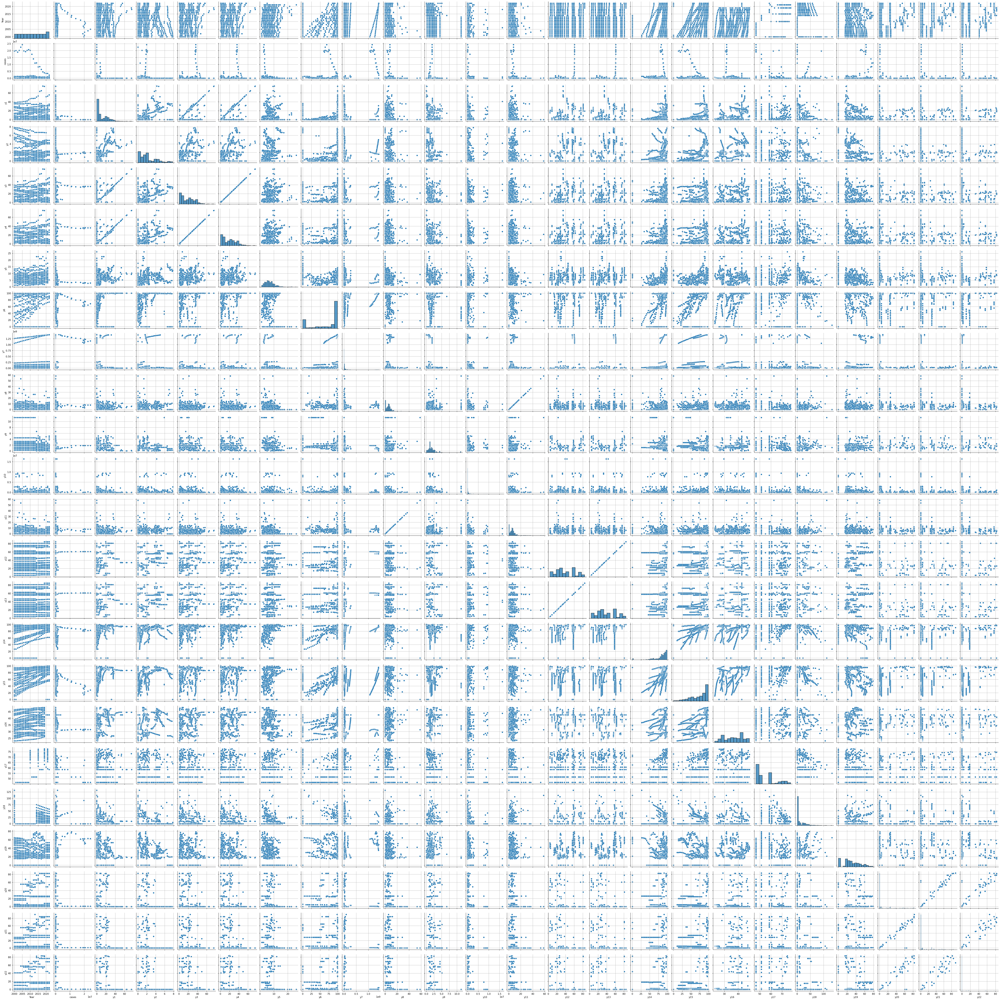

In [5]:
# Histogram
sns.histplot(df["cases"], kde=True)
plt.title("Malaria Cases Distribution")
plt.xlabel("Malaria Cases")
plt.ylabel("Frequency")
plt.show()

sns.pairplot(df)
plt.show()

In [6]:
corr = df[["cases"] + YCOLS].corr()

print(corr)

          cases        y1        y2        y3        y4        y5        y6  \
cases  1.000000 -0.170431 -0.086894  0.180100  0.179997 -0.219856 -0.016933   
y1    -0.170431  1.000000  0.512752  0.497754  0.497811  0.101196  0.351372   
y2    -0.086894  0.512752  1.000000  0.381066  0.381187  0.230761  0.132959   
y3     0.180100  0.497754  0.381066  1.000000  0.999984  0.159347  0.095079   
y4     0.179997  0.497811  0.381187  0.999984  1.000000  0.159314  0.095438   
y5    -0.219856  0.101196  0.230761  0.159347  0.159314  1.000000 -0.149890   
y6    -0.016933  0.351372  0.132959  0.095079  0.095438 -0.149890  1.000000   
y7     0.550226 -0.068547 -0.052526  0.104741  0.104780 -0.119181  0.172391   
y8     0.031197  0.040704 -0.002502 -0.038838 -0.038601 -0.245611  0.336328   
y9    -0.022415 -0.146641 -0.189014 -0.131371 -0.131251 -0.169406 -0.120601   
y10   -0.036512  0.012320  0.042631  0.035254  0.035223  0.021520 -0.021971   
y11    0.031197  0.040704 -0.002502 -0.038838 -0.038

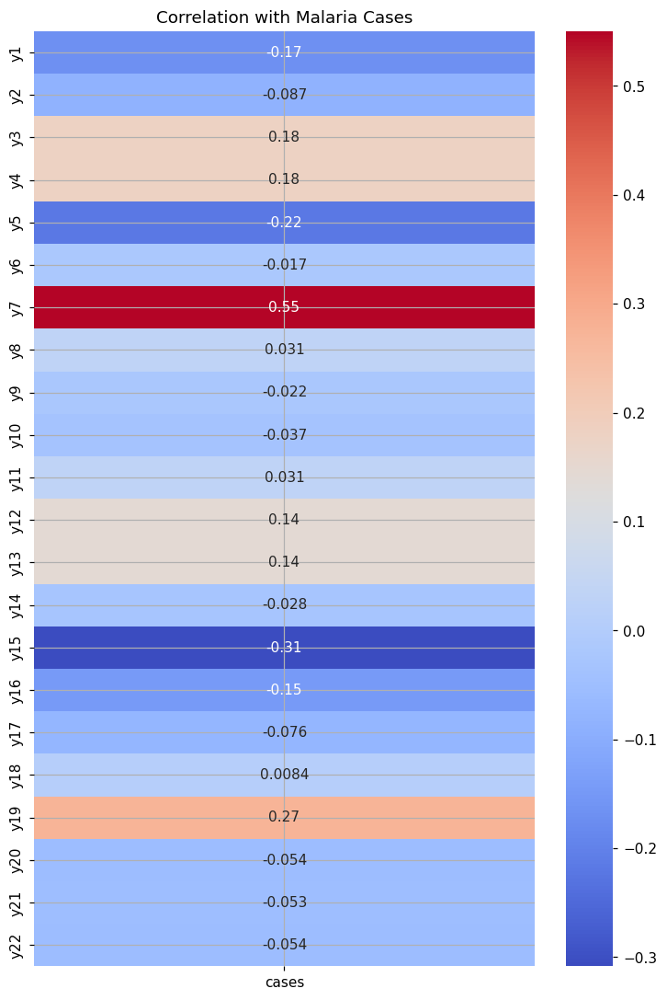

In [7]:
corr = df[["cases"] + YCOLS].corr()["cases"].drop("cases")

plt.figure(figsize=(8, 12))

sns.heatmap(corr.to_frame(), annot=True, cmap="coolwarm")

plt.title("Correlation with Malaria Cases")
plt.show()

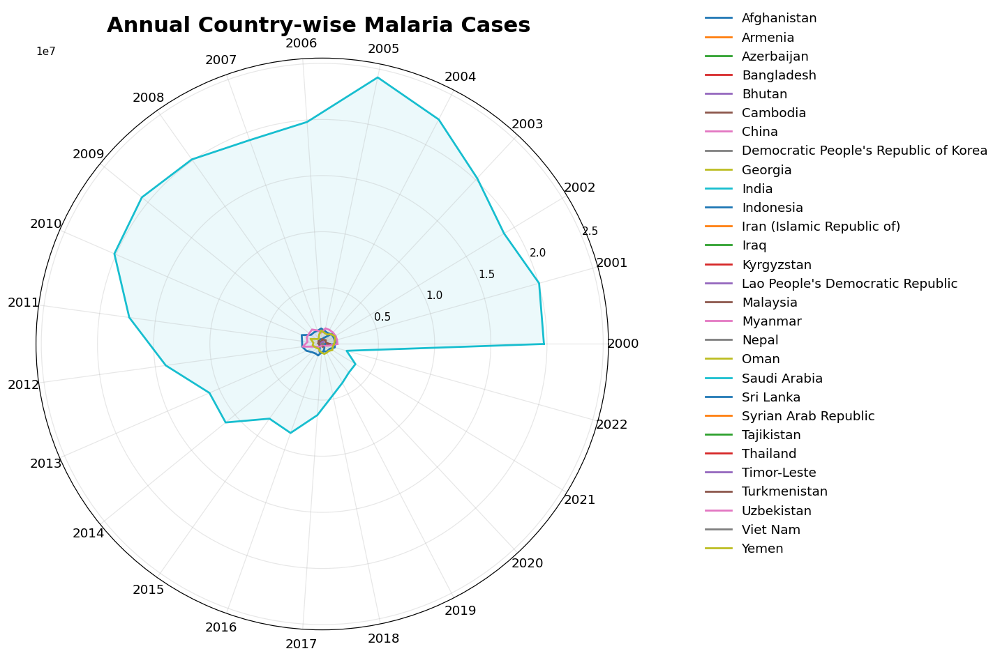

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data
data = df.pivot_table(
    index="Year",
    columns="Country",
    values="cases",
    aggfunc="sum"
).fillna(0)

years = data.index.astype(str)
angles = np.linspace(0, 2*np.pi, len(years), endpoint=False)

# Create radar chart
fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={"polar": True})

for country in data.columns:
    values = data[country].values
    values = np.append(values, values[0])
    plot_angles = np.append(angles, angles[0])

    ax.plot(plot_angles, values, linewidth=1.8, label=country)
    ax.fill(plot_angles, values, alpha=0.08)

# Customize chart
ax.set_xticks(angles)
ax.set_xticklabels(years, fontsize=12)

ax.set_title(
    "Annual Country-wise Malaria Cases ",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.tick_params(axis="y", labelsize=10)
ax.grid(alpha=0.3)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.15, 1.1),
    fontsize=12,
    frameon=False
)

plt.tight_layout()
plt.savefig("Country_Wise_Malaria_Radar.png", dpi=400, bbox_inches="tight")
plt.show()

In [9]:

conda install -c conda-forge geopandas

Jupyter detected...
Note: you may need to restart the kernel to use updated packages.

3 channel Terms of Service accepted
Channels:
 - conda-forge
 - defaults
Platform: win-64


Out of memory allocating 117440512 bytes!


In [11]:
!pip install geopandas

In [14]:

import geopandas as gpd
asia = gpd.read_file(r"C:\Users\HP\Downloads\New folder (7)\ne_110m_admin_0_countries (1)\ne_110m_admin_0_countries.shp")

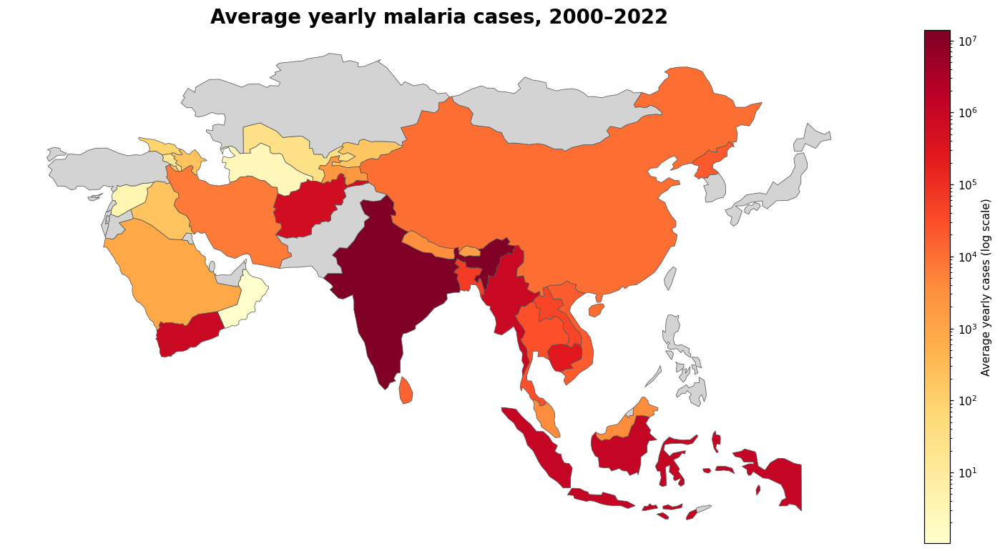

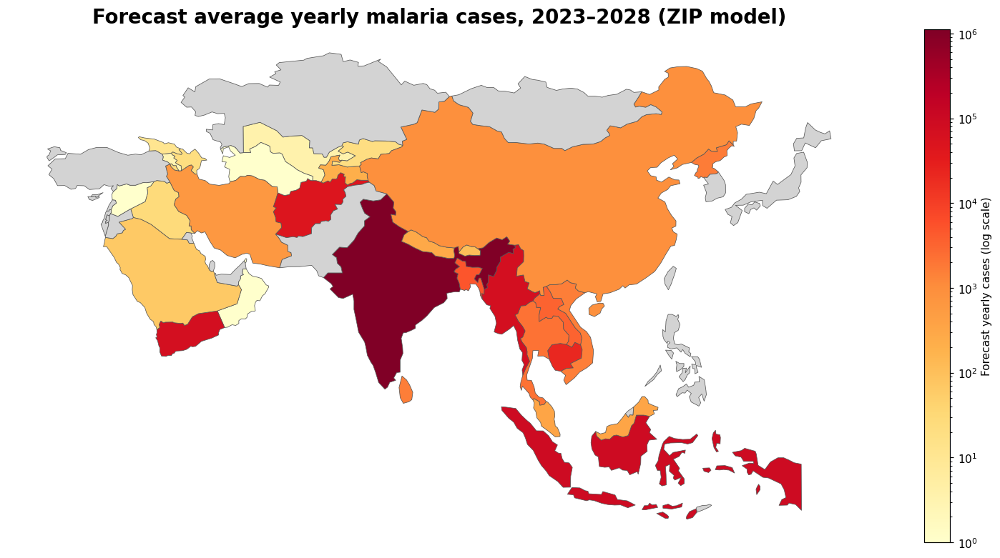

In [17]:
import geopandas as gpd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm

# Prepare data
map_df = df.copy()
map_df["Year"] = pd.to_numeric(map_df["Year"])
map_df["cases"] = pd.to_numeric(map_df["cases"], errors="coerce")
map_df = map_df.dropna(subset=["Country", "Year", "cases"])

# Match common spreadsheet country names to Natural Earth names
country_name_fixes = {
    "Brunei Darussalam": "Brunei",
    "Iran (Islamic Republic of)": "Iran",
    "Democratic People's Republic of Korea": "North Korea",
    "Lao People's Democratic Republic": "Laos",
    "Republic of Korea": "South Korea",
    "Syrian Arab Republic": "Syria",
    "Viet Nam": "Vietnam",
    "Türkiye": "Turkey",
}
map_df["map_country"] = map_df["Country"].replace(country_name_fixes)

# Historical country averages (2000–2022)
historical_avg = (
    map_df[map_df["Year"].between(2000, 2022)]
    .groupby("map_country", as_index=False)["cases"]
    .mean()
    .rename(columns={"cases": "avg_cases"})
)

# ZIP model with country indicators and a linear year trend
COUNTRIES = sorted(map_df["map_country"].unique())

def make_map_X(data):
    X = pd.get_dummies(
        pd.Categorical(data["map_country"], categories=COUNTRIES)
    ).astype(float)
    X.columns = COUNTRIES
    X["t"] = (data["Year"].to_numpy() - 2000) / 10
    return X

def make_map_Z(data):
    return pd.DataFrame({
        "const": 1.0,
        "t": (data["Year"].to_numpy() - 2000) / 10
    })

X = make_map_X(map_df)
Z = make_map_Z(map_df)
zip_model = sm.ZeroInflatedPoisson(
    map_df["cases"].to_numpy(), X, exog_infl=Z, inflation="logit"
)
zip_result = zip_model.fit(method="bfgs", maxiter=5000, disp=0)

# Predict each country for 2023–2028, then average by country
forecast_data = pd.DataFrame(
    [(country, year) for year in range(2023, 2029) for country in COUNTRIES],
    columns=["map_country", "Year"]
)
forecast_X = make_map_X(forecast_data).to_numpy()
forecast_Z = make_map_Z(forecast_data).to_numpy()
params = np.asarray(zip_result.params)

inflation_params = params[:2]
count_params = params[2:]
count_mean = np.exp(count_params @ forecast_X.T)
zero_probability = 1 / (1 + np.exp(-(inflation_params @ forecast_Z.T)))
forecast_data["forecast"] = ((1 - zero_probability) * count_mean).ravel()

forecast_avg = (
    forecast_data.groupby("map_country", as_index=False)["forecast"]
    .mean()
    .rename(columns={"forecast": "avg_forecast"})
)

# Use Natural Earth country names from the shapefile
name_col = "ADMIN" if "ADMIN" in asia.columns else "NAME"
asia_map = asia[asia["CONTINENT"] == "Asia"].copy()

historical_map = asia_map.merge(
    historical_avg, left_on=name_col, right_on="map_country", how="left"
)
forecast_map = asia_map.merge(
    forecast_avg, left_on=name_col, right_on="map_country", how="left"
)

# Plot 1: historical average yearly cases
fig, ax = plt.subplots(figsize=(14, 9))
historical_map.plot(
    column="avg_cases",
    ax=ax,
    cmap="YlOrRd",
    edgecolor="#555555",
    linewidth=0.5,
    missing_kwds={"color": "lightgrey"},
    norm=LogNorm(
        vmin=max(1, historical_map["avg_cases"].min(skipna=True)),
        vmax=historical_map["avg_cases"].max(skipna=True)
    ),
    legend=True,
    legend_kwds={
        "label": "Average yearly cases (log scale)",
        "shrink": 0.75
    }
)
ax.set_title("Average yearly malaria cases, 2000–2022",
             fontsize=18, weight="bold")
ax.axis("off")
plt.tight_layout()
plt.savefig(
    f"{OUT}/map_average_yearly_cases_2000_2022.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# Plot 2: average ZIP forecast for 2023–2028
fig, ax = plt.subplots(figsize=(14, 9))
forecast_map.plot(
    column="avg_forecast",
    ax=ax,
    cmap="YlOrRd",
    edgecolor="#555555",
    linewidth=0.5,
    missing_kwds={"color": "lightgrey"},
    norm=LogNorm(
        vmin=max(1, forecast_map["avg_forecast"].min(skipna=True)),
        vmax=forecast_map["avg_forecast"].max(skipna=True)
    ),
    legend=True,
    legend_kwds={
        "label": "Forecast yearly cases (log scale)",
        "shrink": 0.75
    }
)
ax.set_title("Forecast average yearly malaria cases, 2023–2028 (ZIP model)",
             fontsize=18, weight="bold")
ax.axis("off")
plt.tight_layout()
OUT = r"C:\Users\HP\Downloads\New folder (7)"

plt.savefig(
    f"{OUT}/map_forecast_average_cases_2023_2028_ZIP.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()